In [1]:
# Install the libraries needed for this lab
# (tensorflow is only used for its Tokenizer and pad_sequences helpers;
#  google.colab is already available inside Google Colab)
%pip install -q pandas torch matplotlib tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [3]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
#from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [7]:
df = pd.read_csv("D:/Downloads/NLP Labs/Natural-Language-Processing/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [9]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

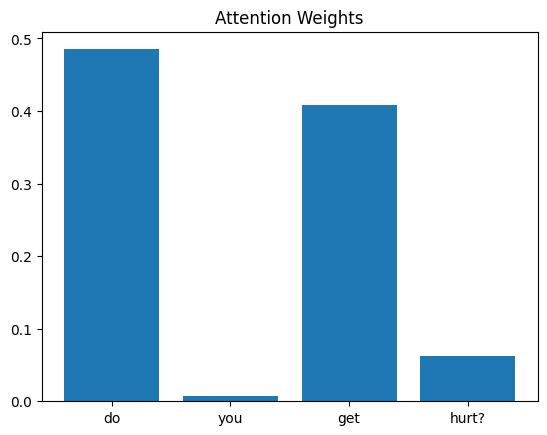

In [11]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

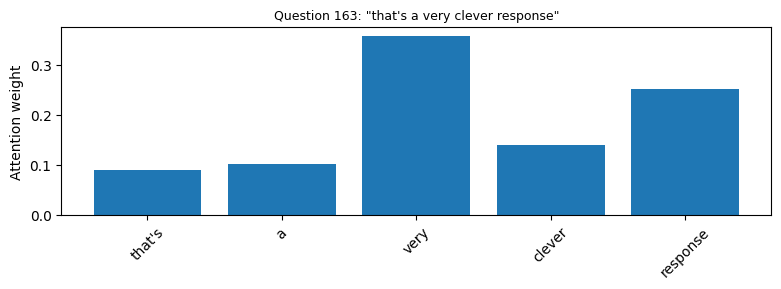

Question 163: "that's a very clever response"
Highest attention: "very" (0.357)



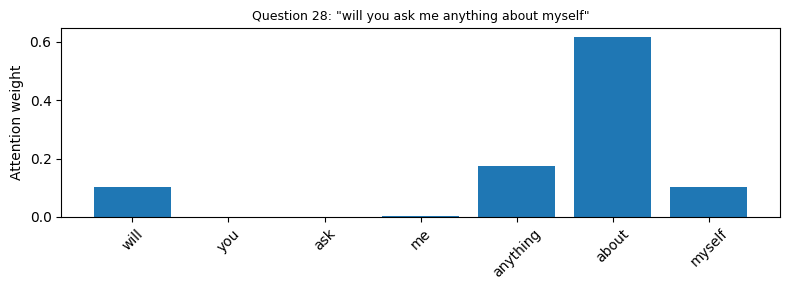

Question 28: "will you ask me anything about myself"
Highest attention: "about" (0.616)



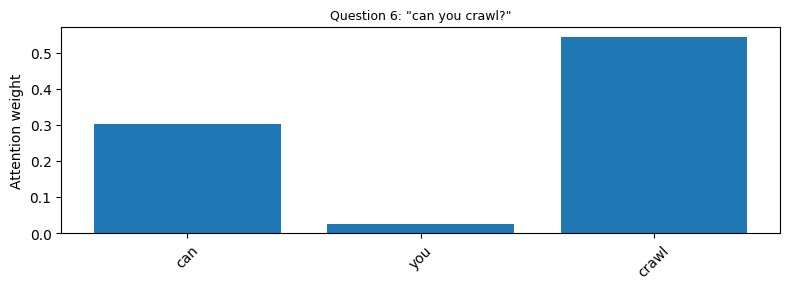

Question 6: "can you crawl?"
Highest attention: "crawl" (0.543)



In [12]:
import random

# Helper: draw the attention bar chart of one question from the dataset (uses the trained model)
def get_attention(idx):
    # words of the question, in the same order and form the model saw them (padding removed)
    words = [tokenizer.index_word[i] for i in X[idx].tolist() if i != 0]
    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])
    weights = weights[0, :len(words)].tolist()
    return words, weights

def plot_attention(idx, ax=None):
    words, weights = get_attention(idx)
    if ax is None:
        plt.figure(figsize=(8, 3))
        ax = plt.gca()
    ax.bar(words, weights)
    ax.set_title(f'Question {idx}: "{df["question"][idx]}"', fontsize=9)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)
    top_word = words[weights.index(max(weights))]
    return top_word, max(weights)

# 1. Select three different questions
random.seed(42)
selected = random.sample(range(len(df)), 3)

# 2. + 3. Bar chart for each question and the word with the highest attention
for idx in selected:
    top_word, top_weight = plot_attention(idx)
    plt.tight_layout()
    plt.show()
    print(f'Question {idx}: "{df["question"][idx]}"')
    print(f'Highest attention: "{top_word}" ({top_weight:.3f})\n')

**Answer (Task 1):** Look at the bar charts above and compare the highest-attention word of each question with the meaning of the question. In general, attention tends to go to the content words that help the model choose the right answer (the topic words of the question), while words like "the", "is", "a" usually receive less weight. However, this is a small model trained for only 50 steps, so the attention is not always perfectly aligned with what a human would consider important, and some weight may be spread almost evenly over all words. So the highest-attention words are often, but not always, the important words, and attention is a hint about what the model used, not a guaranteed explanation.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Answer group: 0
Question A: do you get hurt?
Question B: do you have fingers?
Predicted answer_id for A: 0 | for B: 0


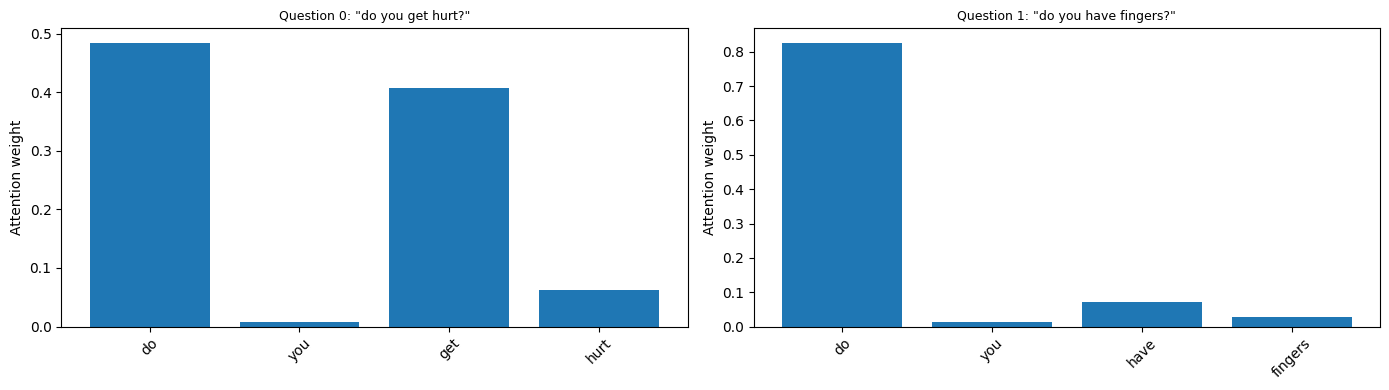


Top words for A: ['do', 'get', 'hurt']
Top words for B: ['do', 'have', 'fingers']
Shared words:    {'do'}


In [13]:
# 1. Pick two questions with similar meaning but different wording:
#    questions that belong to the same answer group (same answer_id) ask for the same thing.
group_sizes = df["answer_id"].value_counts()
group_id = group_sizes[group_sizes >= 2].index[0]
idx_a, idx_b = df.index[df["answer_id"] == group_id][:2]

print("Answer group:", group_id)
print("Question A:", df["question"][idx_a])
print("Question B:", df["question"][idx_b])

# 2. Pass both through the trained model and show the predicted answer
with torch.no_grad():
    pred_a = model(X[idx_a:idx_a + 1])[0].argmax(1).item()
    pred_b = model(X[idx_b:idx_b + 1])[0].argmax(1).item()
print("Predicted answer_id for A:", pred_a, "| for B:", pred_b)

# 3. Visualize the attention weights of both questions side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
top_a, _ = plot_attention(idx_a, axes[0])
top_b, _ = plot_attention(idx_b, axes[1])
plt.tight_layout()
plt.show()

# 4. Compare the words with the highest attention weights (top 3 for each question)
def top_words(idx, k=3):
    words, weights = get_attention(idx)
    ranked = sorted(zip(words, weights), key=lambda p: p[1], reverse=True)[:k]
    return [w for w, _ in ranked]

top_a_words, top_b_words = top_words(idx_a), top_words(idx_b)
print("\nTop words for A:", top_a_words)
print("Top words for B:", top_b_words)
print("Shared words:   ", set(top_a_words) & set(top_b_words) or "none")

**Answer (Task 2):** Compare the top words printed above. When two questions have the same meaning but different wording, the model usually predicts the same answer, but the words it focuses on can be different, because attention is computed from the words that actually appear in each sentence (and their position in the RNN output), not from the meaning directly. Where the two questions share keywords, the attention often lands on those shared words. This suggests that attention works by weighting the words that are most useful for the final prediction, so different phrasing can lead to different attention patterns while still reaching the same answer, and it shows the model relies on key words rather than a full understanding of the sentence.